In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import heapq
import matplotlib.pyplot as plt

In [2]:
def safety_aware_heuristic(current, goal, grid, safety_weight=15.0):
  
    dist_to_goal = np.sqrt((current[0] - goal[0])**2 + (current[1] - goal[1])**2)
    
  
    r, c = current
    rows, cols = grid.shape
    min_dist_to_obs = float('inf')
    
    for dr in range(-3, 4):
        for dc in range(-3, 4):
            nr, nc = r + dr, c + dc
            if 0 <= nr < rows and 0 <= nc < cols:
                if grid[nr, nc] == 1: 
                    d = np.sqrt(dr**2 + dc**2)
                    min_dist_to_obs = min(min_dist_to_obs, d)
    
    
    repulsion = 0
    if min_dist_to_obs <= 3.0:
        repulsion = safety_weight / (min_dist_to_obs + 0.1)**2
        
    return dist_to_goal + repulsion

In [3]:
def weighted_a_star(grid, start, goal, weight):
    
    start, goal = tuple(start), tuple(goal)
    open_set = []
   
    heapq.heappush(open_set, (0, start))
    
    came_from = {}
    g_score = {start: 0}
    f_score = {start: weight * safety_aware_heuristic(start, goal, grid)}
    
    directions = [(0, 1), (1, 0), (0, -1), (-1, 0), (1, 1), (1, -1), (-1, 1), (-1, -1)]
    
    while open_set:
        current = heapq.heappop(open_set)[1]
        
        if current == goal:
            path = []
            while current in came_from:
                path.append(current)
                current = came_from[current]
            path.append(start)
            return path[::-1] 
            
        for dr, dc in directions:
            neighbor = (current[0] + dr, current[1] + dc)
            if 0 <= neighbor[0] < grid.shape[0] and 0 <= neighbor[1] < grid.shape[1]:
                if grid[neighbor[0], neighbor[1]] == 1: continue 
                
                step_cost = np.sqrt(dr**2 + dc**2)
                tentative_g = g_score[current] + step_cost
                
                if neighbor not in g_score or tentative_g < g_score[neighbor]:
                    came_from[neighbor] = current
                    g_score[neighbor] = tentative_g
                    
                    h = safety_aware_heuristic(neighbor, goal, grid)
                    f_score[neighbor] = tentative_g + (weight * h)
                    heapq.heappush(open_set, (f_score[neighbor], neighbor))
                    
    return [] 

In [13]:

class DroneNavigationEnv(gym.Env):
    metadata = {"render_modes": ["human"], "render_fps": 10}

    def __init__(self, grid_size=50, obstacle_density=0.2, render_mode=None):
        super(DroneNavigationEnv, self).__init__()
        self.grid_size = grid_size
        self.obstacle_density = obstacle_density
        self.render_mode = render_mode
        
      
        self.action_space = spaces.Box(low=1.0, high=10.0, shape=(1,), dtype=np.float32)
        
       
        self.observation_space = spaces.Dict({
            "map": spaces.Box(low=0, high=1, shape=(grid_size, grid_size), dtype=np.int8),
            "drone_pos": spaces.Box(low=0, high=grid_size-1, shape=(2,), dtype=np.int32),
            "goal_pos": spaces.Box(low=0, high=grid_size-1, shape=(2,), dtype=np.int32)
        })
        
        self.fig, self.ax = None, None
        self.current_path = []
        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
       
        self.grid = np.random.choice([0, 1], size=(self.grid_size, self.grid_size), 
                                     p=[1-self.obstacle_density, self.obstacle_density]).astype(np.int8)
        
        self.drone_pos = np.array([0, 0], dtype=np.int32)
        self.goal_pos = np.array([self.grid_size - 1, self.grid_size - 1], dtype=np.int32)
        
       
        self.grid[0, 0] = 0
        self.grid[self.grid_size-1, self.grid_size-1] = 0
        
        self.current_path = []
        return self._get_obs(), {}

    def _get_obs(self):
        return {"map": self.grid.copy(), "drone_pos": self.drone_pos.copy(), "goal_pos": self.goal_pos.copy()}

    def step(self, action):
       
        weight = float(action[0])
        path = weighted_a_star(self.grid, self.drone_pos, self.goal_pos, weight)
        self.current_path = path
        
        reward = 0
        if not path:
            reward = -1000 
            terminated = True
        else:
          
            reward += 1000 
          
            dist = sum(np.sqrt((path[i][0]-path[i-1][0])**2 + (path[i][1]-path[i-1][1])**2) for i in range(1, len(path)))
            reward -= (dist * 2.5) 
           
            for node in path:
                if any(self.grid[node[0]+dr, node[1]+dc] == 1 for dr in [-1,0,1] for dc in [-1,0,1] 
                       if 0 <= node[0]+dr < self.grid_size and 0 <= node[1]+dc < self.grid_size):
                    reward -= 5
            
            terminated = True
            self.drone_pos = np.array(path[-1], dtype=np.int32)

        if self.render_mode == "human": self.render()
        return self._get_obs(), reward, terminated, False, {"weight": weight, "path_len": len(path)}

    # def render(self):
        # if self.fig is None:
        #     self.fig, self.ax = plt.subplots(figsize=(7, 7))
        #     plt.ion()
        # self.ax.clear()
        # self.ax.imshow(self.grid, cmap='Greys')
        # self.ax.plot(self.goal_pos[1], self.goal_pos[0], 'gs', markersize=10, label='Goal')
        # if self.current_path:
        #     y, x = zip(*self.current_path)
        #     self.ax.plot(x, y, 'r-', linewidth=2, label='Path')
        # self.ax.legend()
        # plt.draw()
        # plt.pause(0.1)

def render(self):
    if self.fig is None:
        self.fig, self.ax = plt.subplots(figsize=(7, 7))
        plt.ion()

        self.ax.clear()
        self.ax.imshow(self.grid, cmap='Greys')

    # Goal
        self.ax.plot(self.goal_pos[1], self.goal_pos[0], 'gs', markersize=10)

    # Animate drone moving
    if self.current_path:
        for i in range(len(self.current_path)):
            self.ax.clear()
            self.ax.imshow(self.grid, cmap='Greys')

            y, x = self.current_path[i]
            self.ax.plot(x, y, 'ro', markersize=8)  # drone

            # path till now
            py, px = zip(*self.current_path[:i+1])
            self.ax.plot(px, py, 'r-')

            self.ax.plot(self.goal_pos[1], self.goal_pos[0], 'gs', markersize=10)

            plt.draw()                
            plt.pause(0.1)

Starting Drone Navigation Test...


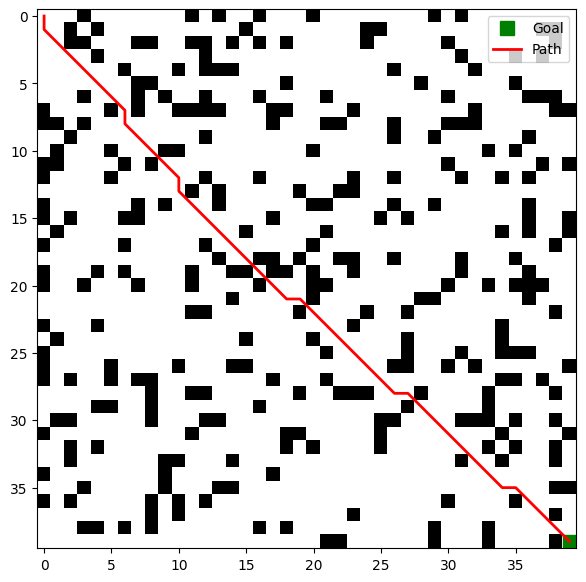

Test 1 | Weight: 1.0 | Reward: 672.7 | Path: 43


<Figure size 640x480 with 0 Axes>

Test 2 | Weight: 3.0 | Reward: 661.3 | Path: 56


<Figure size 640x480 with 0 Axes>

Test 3 | Weight: 5.0 | Reward: 677.5 | Path: 56


<Figure size 640x480 with 0 Axes>

Test 4 | Weight: 7.0 | Reward: 577.1 | Path: 64


<Figure size 640x480 with 0 Axes>

Test 5 | Weight: 9.0 | Reward: 645.6 | Path: 63


In [5]:
if __name__ == "__main__":
    env = DroneNavigationEnv(grid_size=40, render_mode="human")
    print("Starting Drone Navigation Test...")
    for i in range(5):
        obs, info = env.reset()
        
        test_weight = 1.0 + (i * 2.0) 
        obs, reward, done, _, info = env.step([test_weight])
        print(f"Test {i+1} | Weight: {test_weight} | Reward: {reward:.1f} | Path: {info['path_len']}")
    plt.ioff()
    plt.show()

In [6]:
from stable_baselines3 import PPO

In [7]:
from stable_baselines3.common.env_checker import check_env

env = DroneNavigationEnv(grid_size=40)
check_env(env)

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\env_checker.py:316: UserWarning: Your observation map has an unconventional shape (neither an image, nor a 1D vector). We recommend you to flatten the observation to have only a 1D vector or use a custom policy to properly process the data.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\env_checker.py:507: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


In [8]:
model = PPO("MultiInputPolicy", env, verbose=1)

model.learn(total_timesteps=10000)

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 1        |
|    ep_rew_mean     | 638      |
| time/              |          |
|    fps             | 5        |
|    iterations      | 1        |
|    time_elapsed    | 353      |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 1           |
|    ep_rew_mean          | 620         |
| time/                   |             |
|    fps                  | 5           |
|    iterations           | 2           |
|    time_elapsed         | 701         |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.005279339 |
|    clip_fraction        | 0.029       |
|    clip_range           | 0.2         |
|    entropy_loss   

In [9]:
obs, _ = env.reset()

for i in range(5):
    action, _ = model.predict(obs)
    obs, reward, done, _, info = env.step(action)
    
    print(f"RL Weight: {action[0]:.2f} | Reward: {reward:.1f}")
    
    if done:
        obs, _ = env.reset()

RL Weight: 1.00 | Reward: 639.8
RL Weight: 1.00 | Reward: 671.3
RL Weight: 1.00 | Reward: 694.2
RL Weight: 1.53 | Reward: 721.0
RL Weight: 1.00 | Reward: 686.3


In [10]:
# Without RL (fixed weight)
baseline_weight = 1.0
_, reward_base, _, _, _ = env.step([baseline_weight])

# With RL
action, _ = model.predict(obs)
_, reward_rl, _, _, _ = env.step(action)

print("Baseline:", reward_base)
print("RL:", reward_rl)

Baseline: 676.2563132923543
RL: 1000.0


In [11]:
model.save("ppo_drone_model")

In [14]:
from stable_baselines3 import PPO

model = PPO.load("ppo_drone_model")

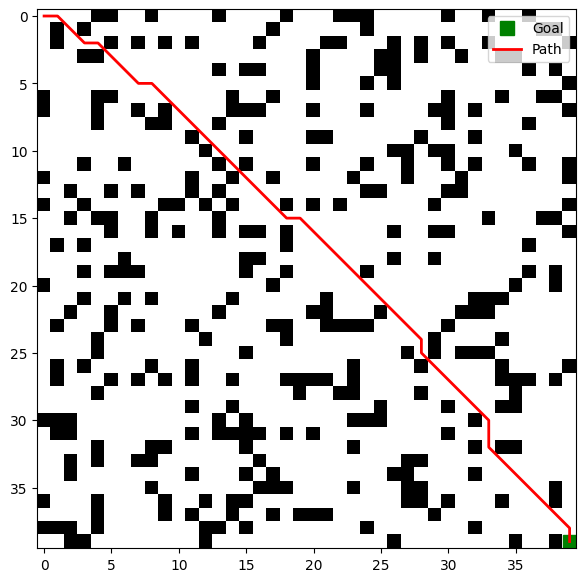

In [16]:
obs, _ = env.reset()

action, _ = model.predict(obs)
obs, reward, done, _, _ = env.step(action)

env.render()

Text(0.5, 1.0, 'RL Drone Navigation | Weight: 1.00')

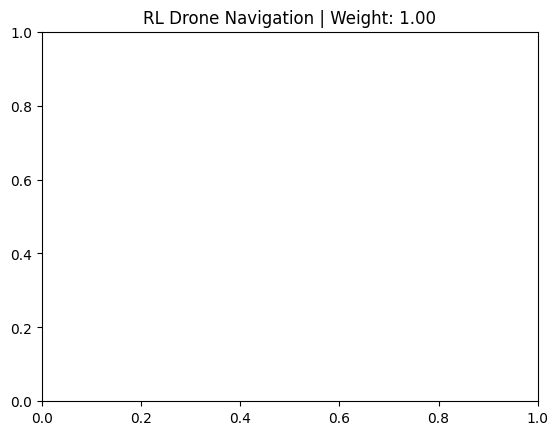

In [17]:
plt.title(f"RL Drone Navigation | Weight: {action[0]:.2f}")

In [18]:
for i in range(3):
    obs, _ = env.reset()
    action, _ = model.predict(obs)
    env.step(action)
    env.render()

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>